# **Product Demand Prediction**

### **Project Overview**
This project implements and compares three different Deep Learning architectures (**ANN, LSTM, and GRU**) for time-series store item demand forecasting. Using chronological historical dataset splits, standard preprocessing techniques, and robust model performance metrics, we identify the best predicting network for demand optimization.

In [1]:

# ==========================================
# 1. IMPORT LIBRARIES AND SETUP
# ==========================================

import os
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

# Plot settings
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")

# Output folders
os.makedirs("models", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("plots", exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

print("\nLibraries imported successfully!")


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Libraries imported successfully!


## **1. Environment Setup & Configuration**
We load core numerical libraries (`numpy`, `pandas`), visualization tools (`matplotlib`, `seaborn`), and establish random seeds to ensure deterministic results across different execution runs.

In [2]:

# ==========================================
# 2. AUTOMATIC DATASET DOWNLOAD
# ==========================================

import urllib.request

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "DharitShah13/"
    "Kaggle-Store-Item-Demand-Forecasting-Challenge/"
    "master/train.csv"
)

DATA_PATH = "train.csv"

if not os.path.exists(DATA_PATH):
    print("Downloading dataset...")

    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

print("Dataset downloaded successfully!")

df = pd.read_csv(DATA_PATH)

print("\nDataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset downloaded successfully!

Dataset shape: (913000, 4)

First five records:


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10



Column names:
['date', 'store', 'item', 'sales']


## **2. Automated Dataset Ingestion**
This block downloads the Kaggle Store Item Demand Forecasting dataset automatically and verifies shape, features, and columns.

In [3]:

# ==========================================
# 3. DATA CLEANING AND PREPROCESSING
# ==========================================

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove duplicates
df.drop_duplicates(inplace=True)

# Convert date column
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove invalid records
df.dropna(subset=["date", "store", "item", "sales"], inplace=True)

# Convert numerical columns
df["store"] = pd.to_numeric(df["store"], errors="coerce")
df["item"] = pd.to_numeric(df["item"], errors="coerce")
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

df.dropna(subset=["store", "item", "sales"], inplace=True)

# Remove invalid negative demand
df = df[df["sales"] >= 0]

# Convert IDs to integers
df["store"] = df["store"].astype(int)
df["item"] = df["item"].astype(int)

# Sort chronologically
df = df.sort_values(
    ["store", "item", "date"]
).reset_index(drop=True)

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned dataset shape:", df.shape)

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

print("\nNumber of stores:", df["store"].nunique())
print("Number of products:", df["item"].nunique())

display(df.head())

# Save cleaned dataset
df.to_csv(
    "results/cleaned_dataset.csv",
    index=False
)

print("\nData cleaning completed!")


Missing values before cleaning:
date     0
store    0
item     0
sales    0
dtype: int64

Missing values after cleaning:
date     0
store    0
item     0
sales    0
dtype: int64

Cleaned dataset shape: (913000, 4)

Date range:
2013-01-01 00:00:00 to 2017-12-31 00:00:00

Number of stores: 10
Number of products: 50


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10



Data cleaning completed!


## **3. Data Cleaning and Validation**
To build a robust pipeline, we perform standard checks including parsing datetime entries, dropping missing records, asserting non-negative demand, and chronologically sorting the records.

Statistical summary:


,date,store,item,sales
count,913000,913000.000000,913000.000000,913000.000000
mean,2015-07-02 11:59:59.999999744,5.500000,25.500000,52.250287
min,2013-01-01 00:00:00,1.000000,1.000000,0.000000
25%,2014-04-02 00:00:00,3.000000,13.000000,30.000000
50%,2015-07-02 12:00:00,5.500000,25.500000,47.000000
75%,2016-10-01 00:00:00,8.000000,38.000000,70.000000
max,2017-12-31 00:00:00,10.000000,50.000000,231.000000
std,NaN,2.872283,14.430878,28.801144


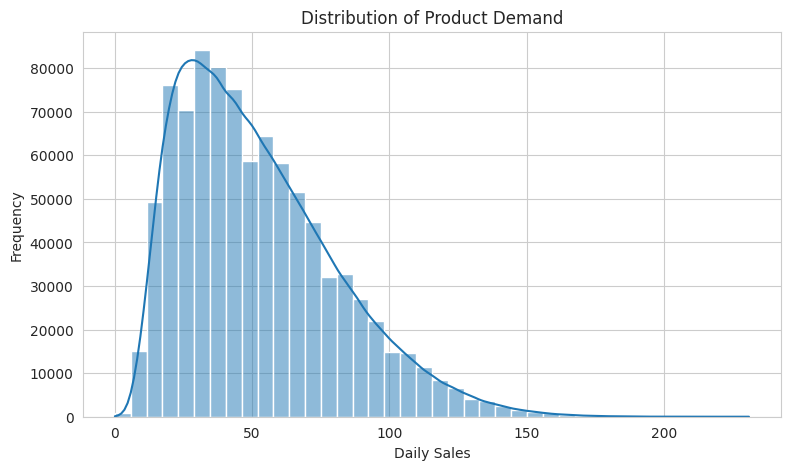

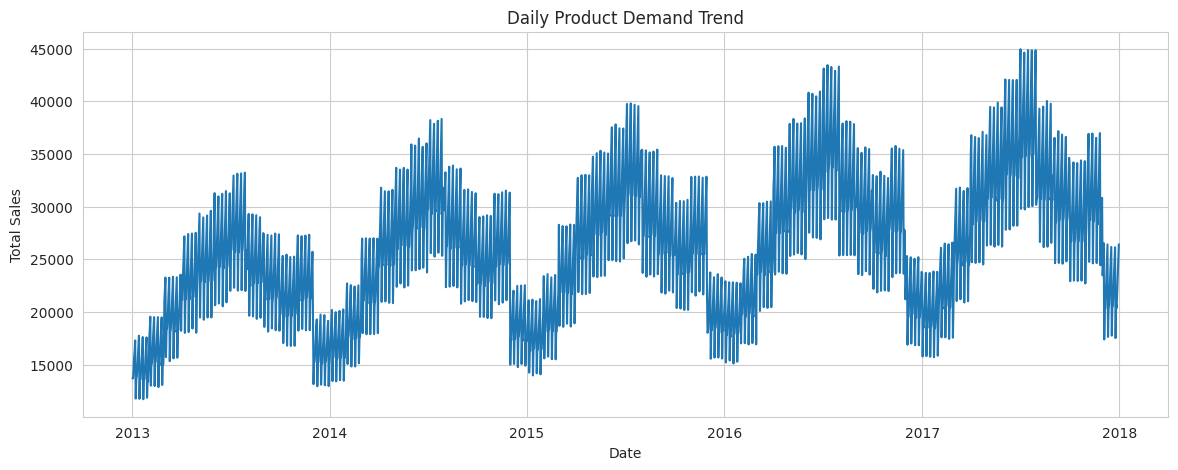

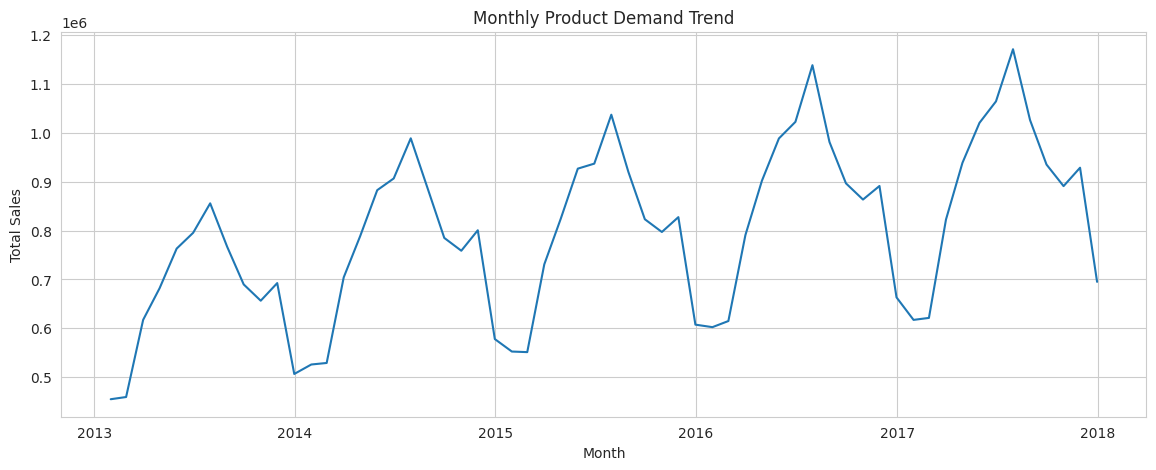

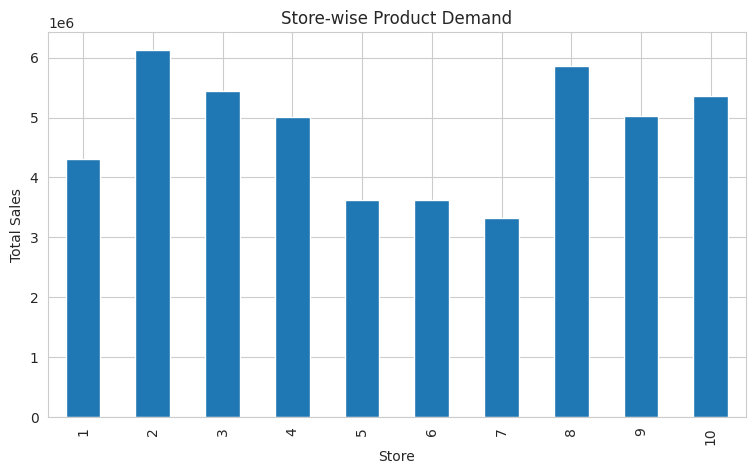

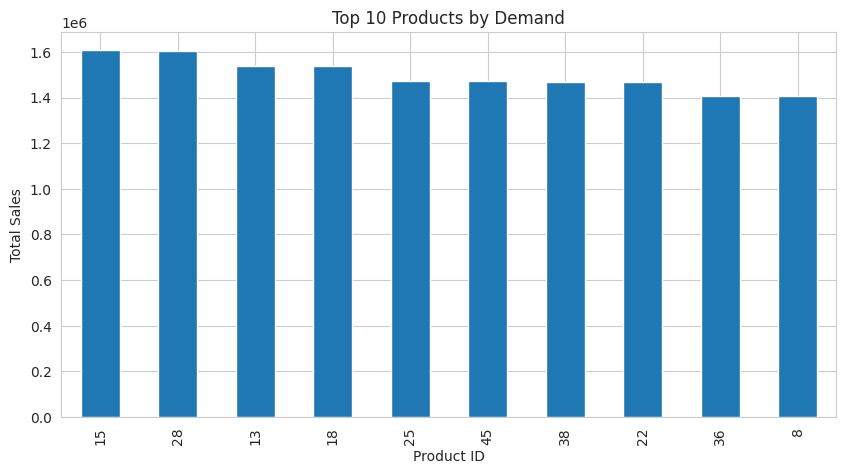

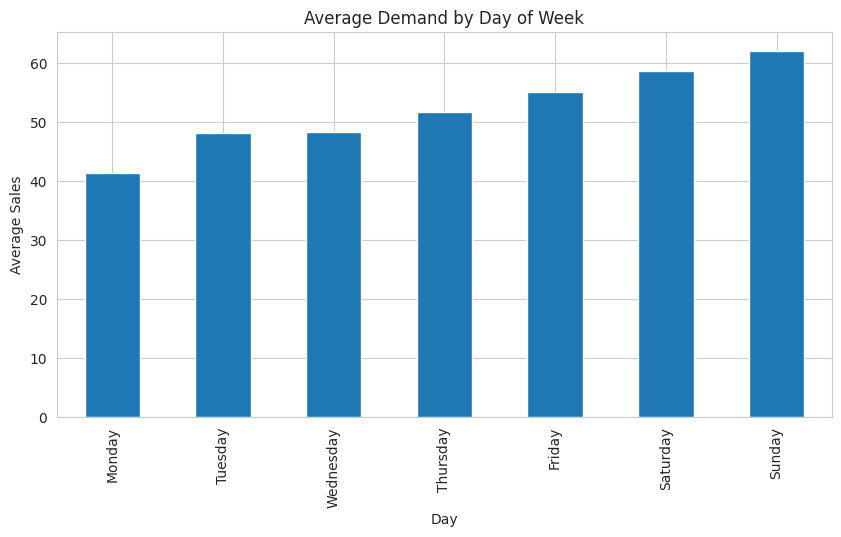

EDA completed successfully!


In [4]:

# ==========================================
# 4. EXPLORATORY DATA ANALYSIS
# ==========================================

# Dataset statistics
print("Statistical summary:")
display(df.describe())

# 1. Sales distribution
plt.figure(figsize=(9, 5))
sns.histplot(df["sales"], bins=40, kde=True)
plt.title("Distribution of Product Demand")
plt.xlabel("Daily Sales")
plt.ylabel("Frequency")
plt.savefig("plots/01_sales_distribution.png")
plt.show()

# 2. Daily sales trend
daily_sales = df.groupby("date")["sales"].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales.index, daily_sales.values)
plt.title("Daily Product Demand Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.savefig("plots/02_daily_sales.png")
plt.show()

# 3. Monthly sales trend
monthly_sales = (
    df.set_index("date")["sales"]
    .resample("ME")
    .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Product Demand Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.savefig("plots/03_monthly_sales.png")
plt.show()

# 4. Store-wise sales
store_sales = df.groupby("store")["sales"].sum()

plt.figure(figsize=(9, 5))
store_sales.plot(kind="bar")
plt.title("Store-wise Product Demand")
plt.xlabel("Store")
plt.ylabel("Total Sales")
plt.savefig("plots/04_store_sales.png")
plt.show()

# 5. Top 10 products
product_sales = (
    df.groupby("item")["sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
product_sales.plot(kind="bar")
plt.title("Top 10 Products by Demand")
plt.xlabel("Product ID")
plt.ylabel("Total Sales")
plt.savefig("plots/05_product_sales.png")
plt.show()

# 6. Weekly demand pattern
df["day_of_week"] = df["date"].dt.day_name()

weekly_sales = (
    df.groupby("day_of_week")["sales"]
    .mean()
    .reindex([
        "Monday", "Tuesday", "Wednesday",
        "Thursday", "Friday", "Saturday", "Sunday"
    ])
)

plt.figure(figsize=(10, 5))
weekly_sales.plot(kind="bar")
plt.title("Average Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")
plt.savefig("plots/06_weekly_demand.png")
plt.show()

print("EDA completed successfully!")


## **4. Exploratory Data Analysis (EDA)**
Understanding seasonality, distributions, store behaviors, and baseline trends via visual graphics and aggregation checks.

In [5]:

# ==========================================
# 5. TIME SERIES PREPROCESSING
# ==========================================

LOOKBACK = 28

# Chronological split
unique_dates = np.sort(df["date"].unique())

train_end = unique_dates[
    int(len(unique_dates) * 0.70) - 1
]

val_end = unique_dates[
    int(len(unique_dates) * 0.85) - 1
]

print("Training ends:", train_end)
print("Validation ends:", val_end)
print("Testing starts:", val_end)

# Fit scaler only on training-period sales
scaler = MinMaxScaler()

train_values = df.loc[
    df["date"] <= train_end, ["sales"]
]

scaler.fit(train_values)

df["scaled_sales"] = scaler.transform(
    df[["sales"]]
).flatten()

# Sequence creation
def create_sequences(data, lookback=28):

    X_train, y_train = [], []
    X_val, y_val = [], []
    X_test, y_test = [], []

    train_dates = []
    val_dates = []
    test_dates = []

    train_actual = []
    val_actual = []
    test_actual = []

    for (store, item), group in data.groupby(
        ["store", "item"]
    ):

        group = group.sort_values("date")

        values = group["scaled_sales"].values
        actual_values = group["sales"].values
        dates = group["date"].values

        for i in range(lookback, len(group)):

            target_date = dates[i]

            x = values[i-lookback:i].reshape(
                lookback, 1
            )

            y = values[i]

            actual = actual_values[i]

            if target_date <= train_end:

                # Reduce training sequences
                if i % 7 == 0:
                    X_train.append(x)
                    y_train.append(y)
                    train_dates.append(target_date)
                    train_actual.append(actual)

            elif target_date <= val_end:

                X_val.append(x)
                y_val.append(y)
                val_dates.append(target_date)
                val_actual.append(actual)

            else:

                X_test.append(x)
                y_test.append(y)
                test_dates.append(target_date)
                test_actual.append(actual)

    return (
        np.array(X_train, dtype=np.float32),
        np.array(y_train, dtype=np.float32),

        np.array(X_val, dtype=np.float32),
        np.array(y_val, dtype=np.float32),

        np.array(X_test, dtype=np.float32),
        np.array(y_test, dtype=np.float32),

        np.array(train_dates),
        np.array(val_dates),
        np.array(test_dates),

        np.array(train_actual),
        np.array(val_actual),
        np.array(test_actual)
    )


(
    X_train, y_train,
    X_val, y_val,
    X_test, y_test,
    train_dates, val_dates, test_dates,
    train_actual, val_actual, test_actual
) = create_sequences(df, LOOKBACK)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

print("\nSequence creation completed!")


Training ends: 2016-07-01T00:00:00.000000000
Validation ends: 2017-04-01T00:00:00.000000000
Testing starts: 2017-04-01T00:00:00.000000000
Training shape: (89500, 28, 1)
Validation shape: (137000, 28, 1)
Testing shape: (137000, 28, 1)

Sequence creation completed!


## **5. Sequence Generation & Scaling**
We scale values using a MinMaxScaler fitted only on the training interval, then construct 3D sequence arrays (`[samples, lookback, features]`) necessary for Recurrent Neural Networks.

In [6]:

# ==========================================
# 6. MODEL ARCHITECTURES
# ==========================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Dense,
    Flatten,
    Dropout,
    LSTM,
    GRU
)

from tensorflow.keras.optimizers import Adam

# ANN Model
def build_ann():

    model = Sequential([
        tf.keras.Input(shape=(LOOKBACK, 1)),

        Flatten(),

        Dense(128, activation="relu"),

        Dropout(0.2),

        Dense(64, activation="relu"),

        Dense(32, activation="relu"),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


# LSTM Model
def build_lstm():

    model = Sequential([
        tf.keras.Input(shape=(LOOKBACK, 1)),

        LSTM(64, return_sequences=True),

        Dropout(0.2),

        LSTM(32),

        Dense(32, activation="relu"),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


# GRU Model
def build_gru():

    model = Sequential([
        tf.keras.Input(shape=(LOOKBACK, 1)),

        GRU(64, return_sequences=True),

        Dropout(0.2),

        GRU(32),

        Dense(32, activation="relu"),

        Dense(1)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


print("ANN, LSTM and GRU architectures created!")


ANN, LSTM and GRU architectures created!


## **6. Deep Learning Architectures**
We initialize our model definitions: a baseline Artificial Neural Network (ANN), a Long Short-Term Memory Network (LSTM), and a Gated Recurrent Unit Network (GRU).

In [7]:

# ==========================================
# 7. TRAINING ALL THREE MODELS
# ==========================================

EPOCHS = 100
BATCH_SIZE = 256

models = {
    "ANN": build_ann(),
    "LSTM": build_lstm(),
    "GRU": build_gru()
}

histories = {}
training_times = {}

for name, model in models.items():

    print("\n" + "=" * 50)
    print("Training", name)
    print("=" * 50)

    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    start_time = time.time()

    history = model.fit(
        X_train,
        y_train,

        validation_data=(X_val, y_val),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=[early_stop],

        verbose=1,
        shuffle=True
    )

    end_time = time.time()

    histories[name] = history

    training_times[name] = (
        end_time - start_time
    )

    print(
        f"{name} training time:",
        round(training_times[name], 2),
        "seconds"
    )

print("\nAll models trained successfully!")



Training ANN
Epoch 1/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 9s 16ms/step - loss: 0.0023 - mae: 0.0343 - val_loss: 0.0069 - val_mae: 0.0610
Epoch 2/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0016 - mae: 0.0306 - val_loss: 0.0074 - val_mae: 0.0648
Epoch 3/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0016 - mae: 0.0302 - val_loss: 0.0072 - val_mae: 0.0638
Epoch 4/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0015 - mae: 0.0300 - val_loss: 0.0076 - val_mae: 0.0656
Epoch 5/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0015 - mae: 0.0298 - val_loss: 0.0076 - val_mae: 0.0654
Epoch 6/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0015 - mae: 0.0297 - val_loss: 0.0078 - val_mae: 0.0668
Epoch 7/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0015 - mae: 0.0296 - val_loss: 0.0078 - val_mae: 0.0663
Epoch 8/100
350/350 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0015 - mae: 0.0296 - val_loss: 0.0078 - val_mae: 0.0662
Epoch 9/100
350/350 ━━━━━━━━━━━━━

## **7. Training Loop & Validation Tracking**
All three models are systematically trained using an Early Stopping callback monitor to save weights when validation loss stops improving.

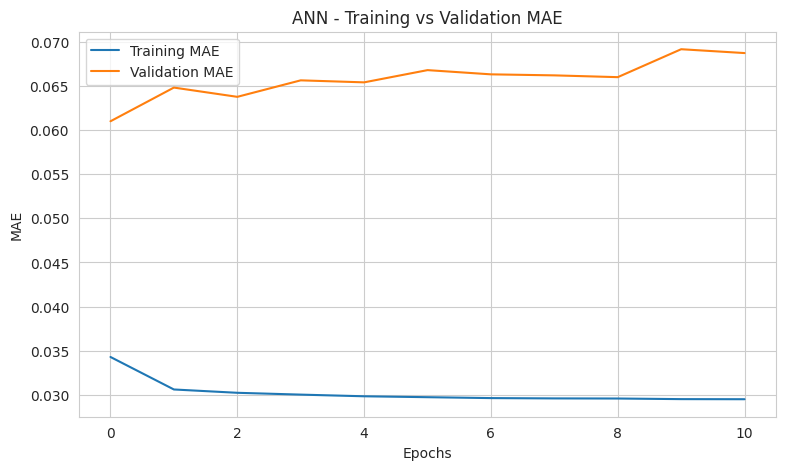

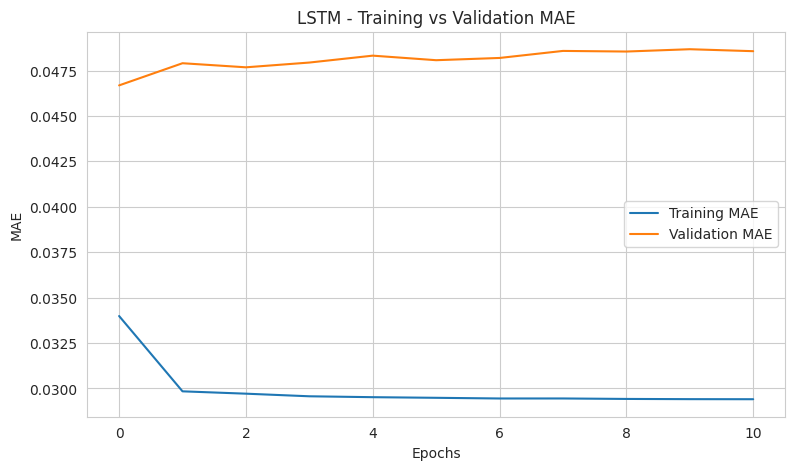

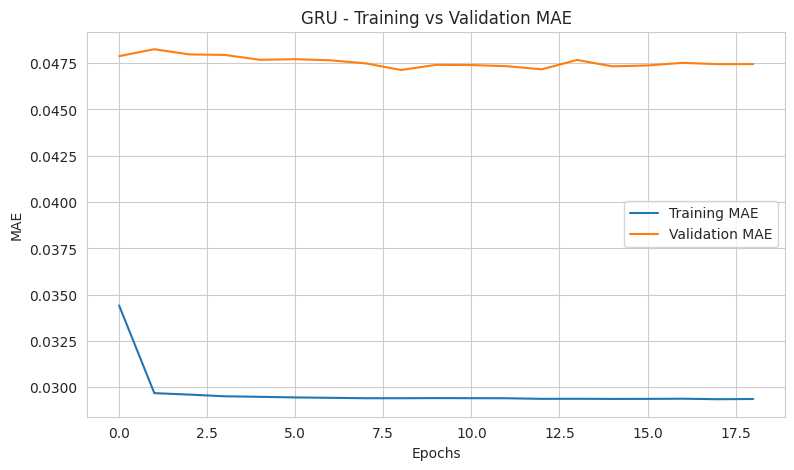

MAE graphs generated!


In [8]:

# ==========================================
# 9. TRAINING MAE GRAPHS
# ==========================================

for name, history in histories.items():

    plt.figure(figsize=(9, 5))

    plt.plot(
        history.history["mae"],
        label="Training MAE"
    )

    plt.plot(
        history.history["val_mae"],
        label="Validation MAE"
    )

    plt.title(name + " - Training vs Validation MAE")

    plt.xlabel("Epochs")
    plt.ylabel("MAE")

    plt.legend()

    plt.savefig(
        f"plots/{name}_mae.png"
    )

    plt.show()

print("MAE graphs generated!")


## **8. Performance Metrics and Comparative Evaluation**
We construct comparative reports checking metrics such as Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Weighted Absolute Percentage Error (WAPE).

In [9]:

# ==========================================
# 10. MODEL PREDICTIONS
# ==========================================

predictions = {}

# Actual values in original scale
y_test_actual = test_actual.astype(float)

for name, model in models.items():

    print("Predicting with", name)

    pred_scaled = model.predict(
        X_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    pred_actual = scaler.inverse_transform(
        pred_scaled
    ).flatten()

    # Demand cannot be negative
    pred_actual = np.maximum(pred_actual, 0)

    predictions[name] = pred_actual

print("\nAll predictions generated!")

print("Actual values:", y_test_actual[:10])

for name in predictions:
    print(name, ":", predictions[name][:10])


Predicting with ANN
Predicting with LSTM
Predicting with GRU

All predictions generated!
Actual values: [21. 17. 22. 21. 25. 25. 23. 20. 19. 21.]
ANN : [15.757785 16.44542  16.577105 15.76544  16.339212 17.31689  17.971424
 17.922104 17.633347 17.48651 ]
LSTM : [16.78578  16.899668 16.984873 17.152004 17.347898 17.675339 18.088581
 18.50395  18.80428  18.994434]
GRU : [16.541199 17.075348 16.90425  17.323015 17.650276 18.45151  19.213041
 19.590683 19.45074  19.122513]


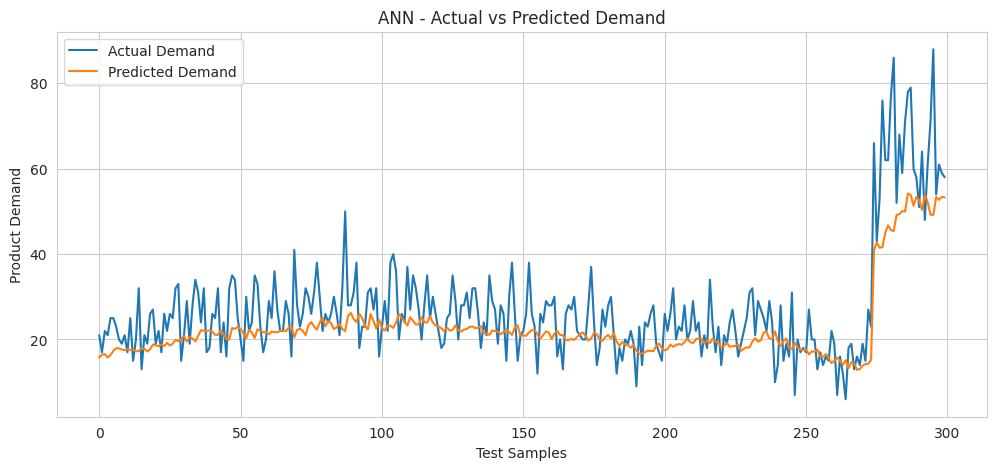

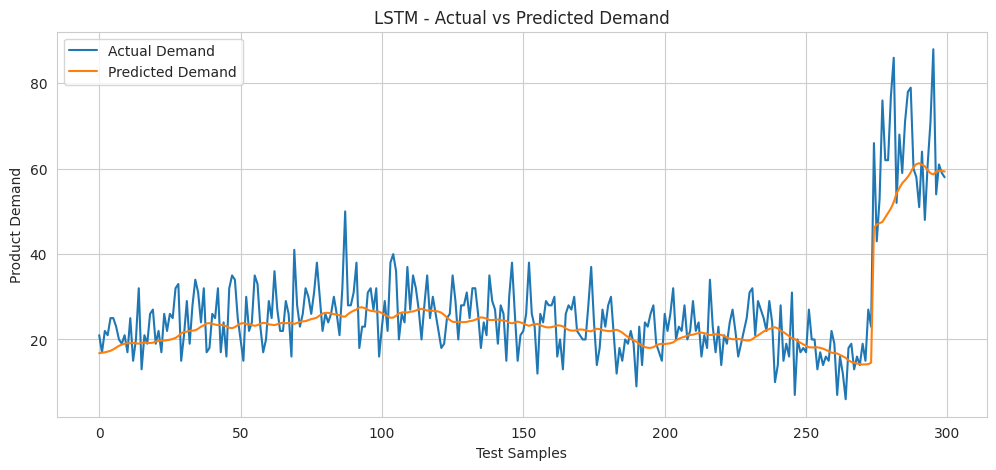

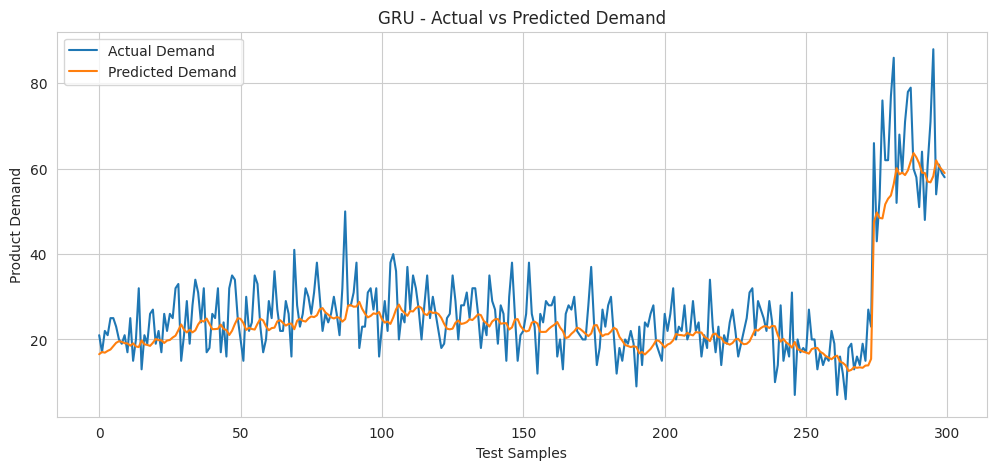

Actual vs predicted graphs generated!


In [10]:

# ==========================================
# 11. ACTUAL VS PREDICTED GRAPHS
# ==========================================

for name, pred in predictions.items():

    plt.figure(figsize=(12, 5))

    plt.plot(
        y_test_actual[:300],
        label="Actual Demand"
    )

    plt.plot(
        pred[:300],
        label="Predicted Demand"
    )

    plt.title(name + " - Actual vs Predicted Demand")

    plt.xlabel("Test Samples")
    plt.ylabel("Product Demand")

    plt.legend()

    plt.savefig(
        f"plots/{name}_actual_vs_predicted.png"
    )

    plt.show()

print("Actual vs predicted graphs generated!")


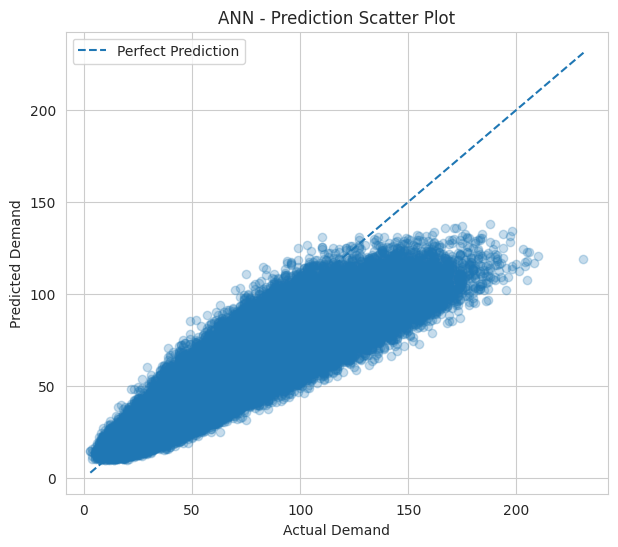

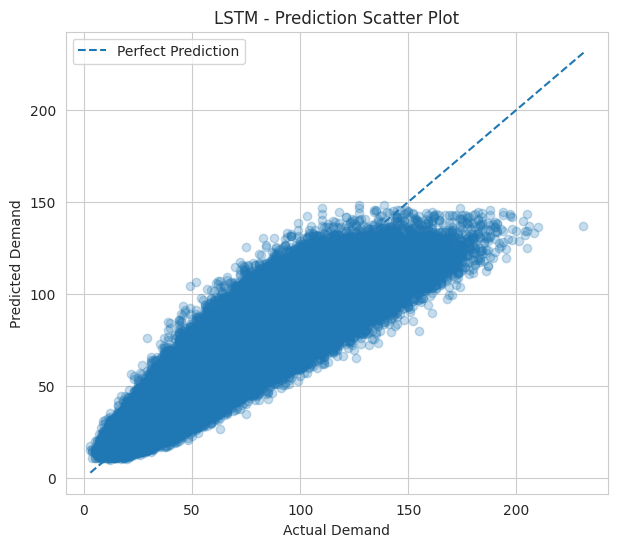

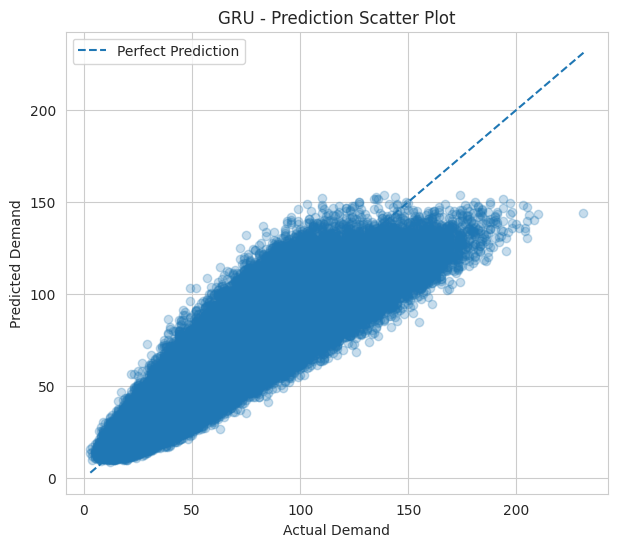

Scatter plots generated!


In [11]:

# ==========================================
# 12. PREDICTION SCATTER PLOTS
# ==========================================

for name, pred in predictions.items():

    plt.figure(figsize=(7, 6))

    plt.scatter(
        y_test_actual,
        pred,
        alpha=0.25
    )

    min_value = min(
        y_test_actual.min(),
        pred.min()
    )

    max_value = max(
        y_test_actual.max(),
        pred.max()
    )

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--",
        label="Perfect Prediction"
    )

    plt.title(name + " - Prediction Scatter Plot")

    plt.xlabel("Actual Demand")
    plt.ylabel("Predicted Demand")

    plt.legend()

    plt.savefig(
        f"plots/{name}_scatter.png"
    )

    plt.show()

print("Scatter plots generated!")


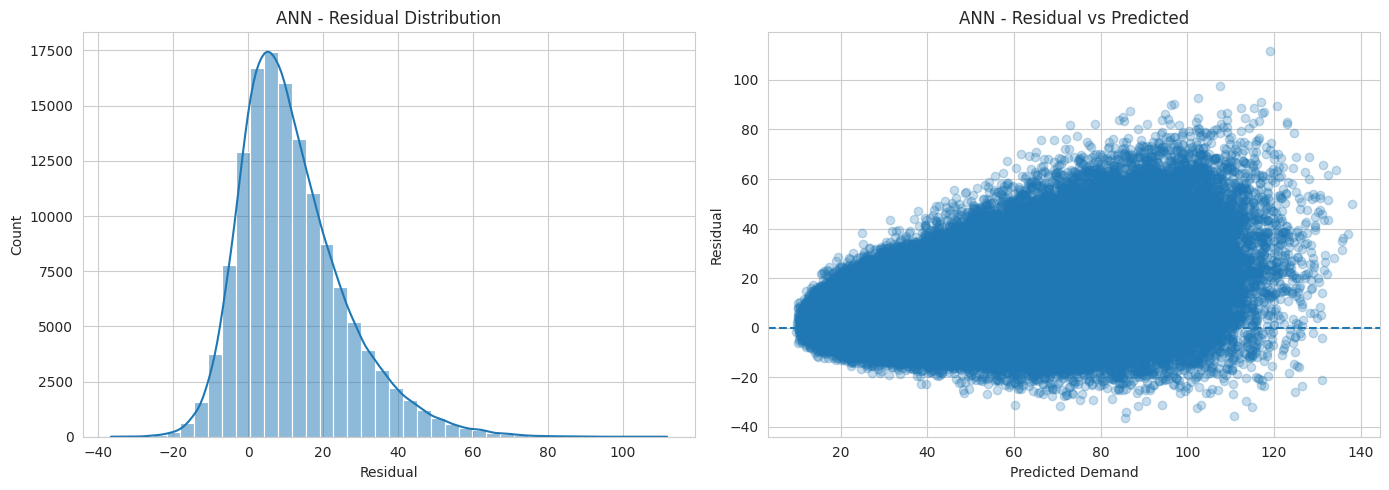

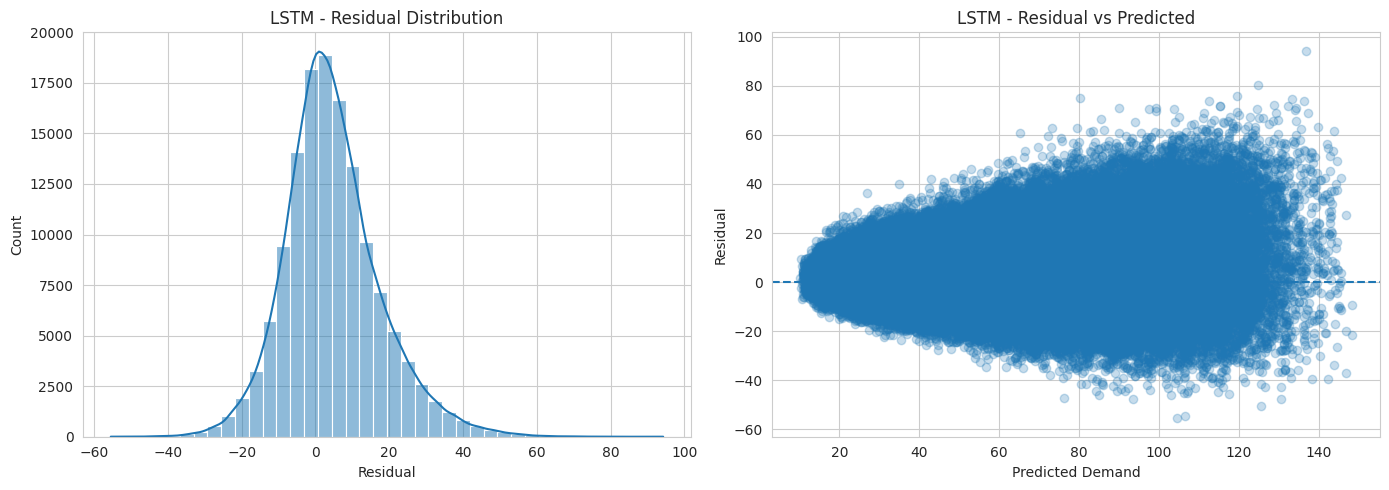

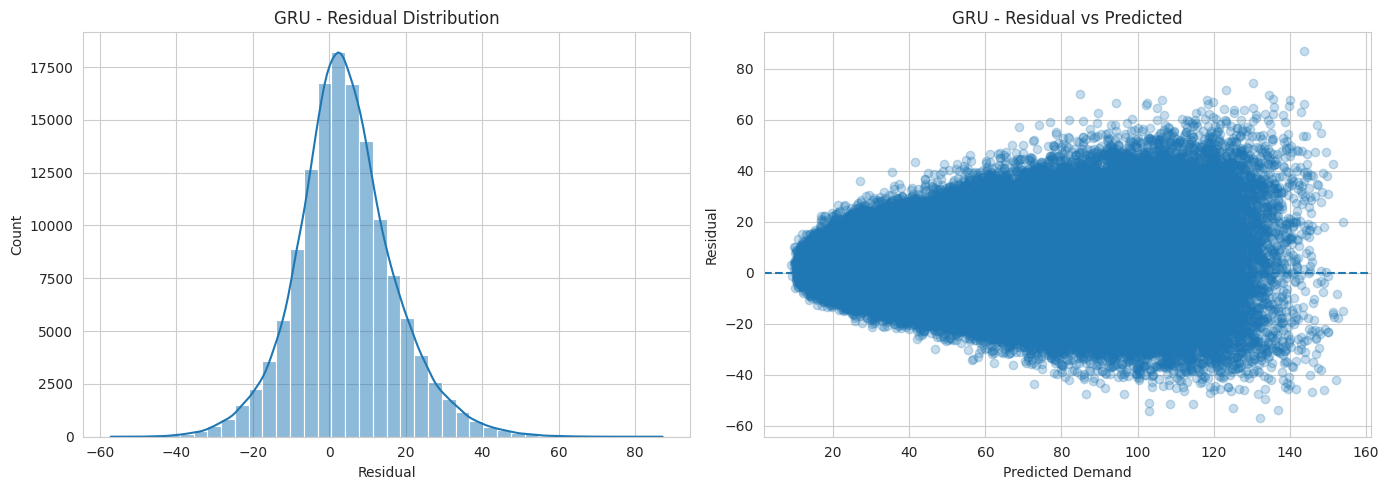

Residual analysis completed!


In [12]:

# ==========================================
# 13. RESIDUAL ANALYSIS
# ==========================================

residuals = {}

for name, pred in predictions.items():

    residual = y_test_actual - pred

    residuals[name] = residual

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Residual distribution
    sns.histplot(
        residual,
        bins=40,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(
        name + " - Residual Distribution"
    )

    axes[0].set_xlabel("Residual")

    # Residual vs predicted
    axes[1].scatter(
        pred,
        residual,
        alpha=0.25
    )

    axes[1].axhline(
        0,
        linestyle="--"
    )

    axes[1].set_title(
        name + " - Residual vs Predicted"
    )

    axes[1].set_xlabel("Predicted Demand")
    axes[1].set_ylabel("Residual")

    plt.tight_layout()

    plt.savefig(
        f"plots/{name}_residual_analysis.png"
    )

    plt.show()

print("Residual analysis completed!")


In [13]:

# ==========================================
# 14. MODEL EVALUATION
# ==========================================

def calculate_metrics(actual, predicted):

    mae = mean_absolute_error(
        actual, predicted
    )

    mse = mean_squared_error(
        actual, predicted
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        actual, predicted
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / max(np.sum(np.abs(actual)), 1e-10)
    ) * 100

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2,
        "WAPE": wape
    }


results = []

for name, pred in predictions.items():

    metrics = calculate_metrics(
        y_test_actual,
        pred
    )

    metrics["Model"] = name

    metrics["Training_Time"] = (
        training_times[name]
    )

    results.append(metrics)


results_df = pd.DataFrame(results)

results_df = results_df[
    [
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2",
        "WAPE",
        "Training_Time"
    ]
]

print("MODEL PERFORMANCE COMPARISON")

display(
    results_df.round(4)
)

results_df.to_csv(
    "results/model_evaluation.csv",
    index=False
)


MODEL PERFORMANCE COMPARISON


,Model,MAE,MSE,RMSE,R2,WAPE,Training_Time
0,ANN,13.7768,342.5649,18.5085,0.6775,21.8510,32.6798
1,LSTM,10.2367,189.1501,13.7532,0.8219,16.2363,65.5562
2,GRU,10.2782,184.5256,13.5840,0.8263,16.3021,107.2236


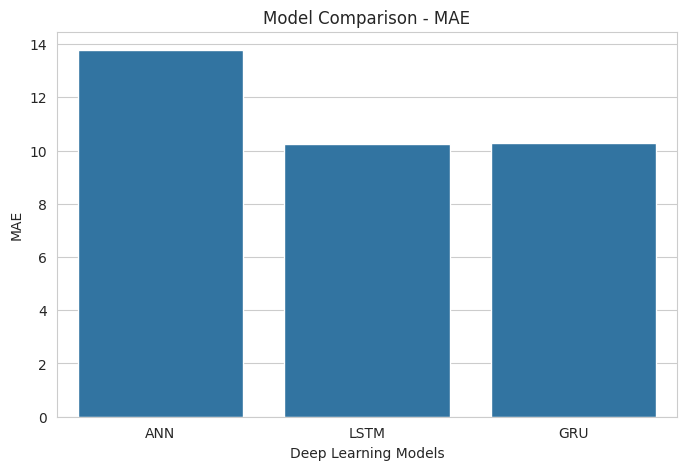

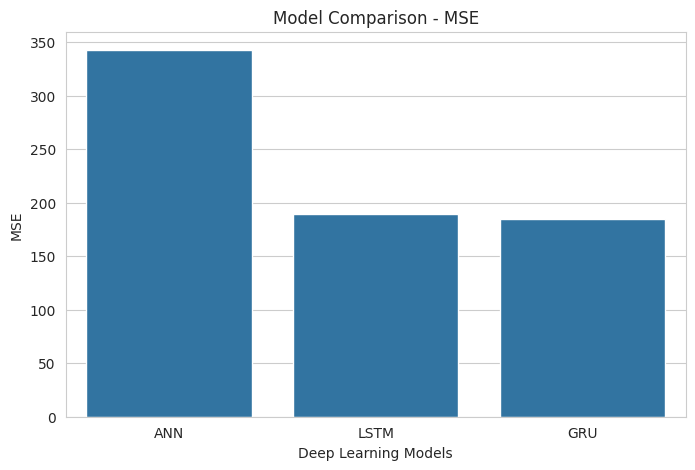

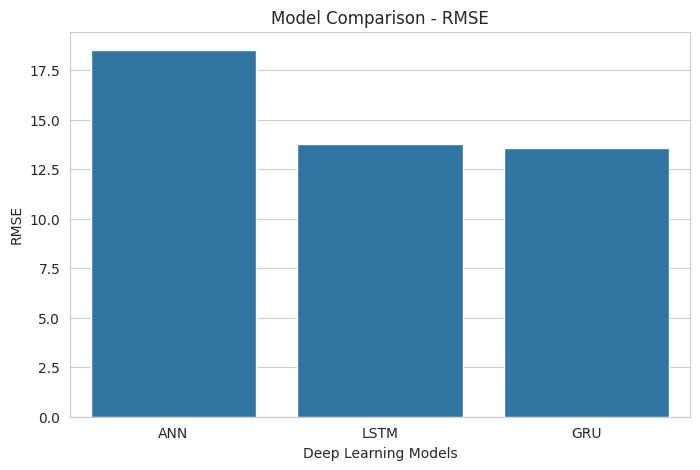

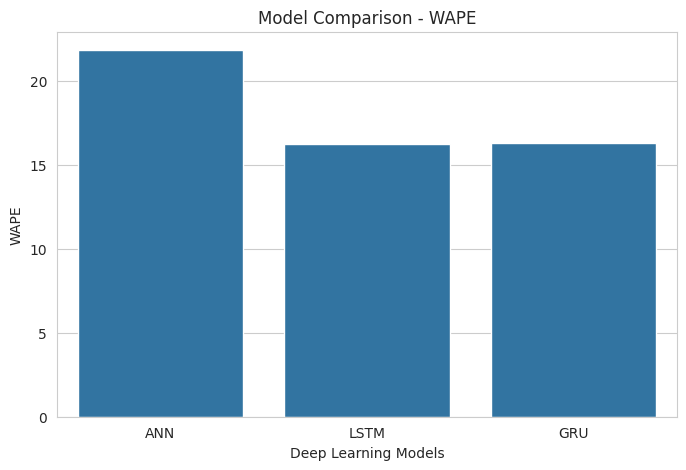

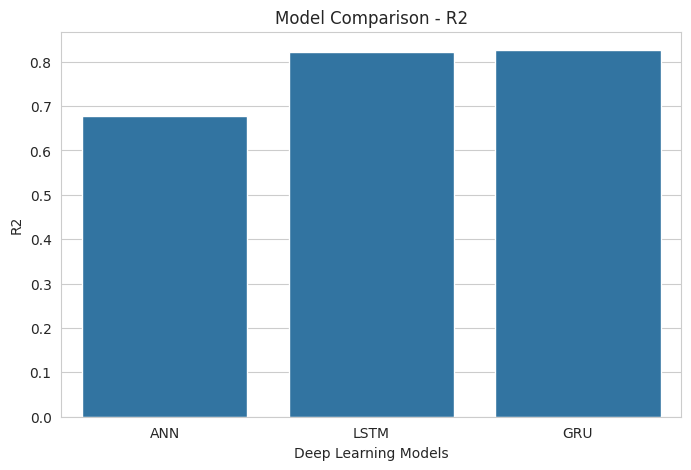

Performance comparison graphs generated!


In [14]:

# ==========================================
# 15. MODEL PERFORMANCE COMPARISON
# ==========================================

metrics_to_plot = [
    "MAE",
    "MSE",
    "RMSE",
    "WAPE",
    "R2"
]

for metric in metrics_to_plot:

    plt.figure(figsize=(8, 5))

    sns.barplot(
        data=results_df,
        x="Model",
        y=metric
    )

    plt.title(
        "Model Comparison - " + metric
    )

    plt.xlabel("Deep Learning Models")
    plt.ylabel(metric)

    plt.savefig(
        f"plots/comparison_{metric}.png"
    )

    plt.show()

print("Performance comparison graphs generated!")


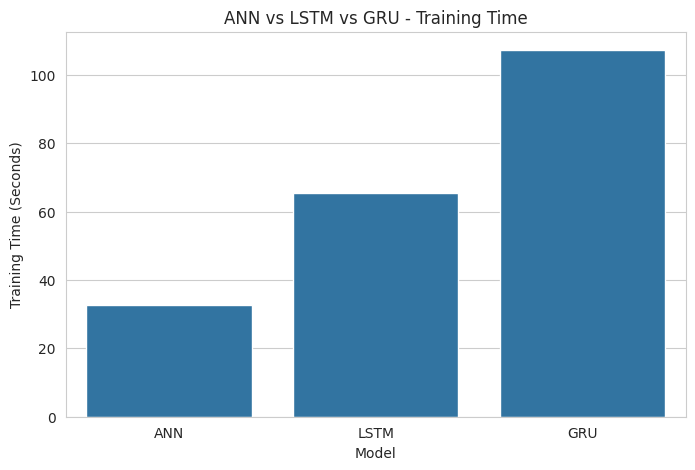


Training Time:


,Model,Training_Time
0,ANN,32.679789
1,LSTM,65.556199
2,GRU,107.223561


In [15]:

# ==========================================
# 16. TRAINING TIME COMPARISON
# ==========================================

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Training_Time"
)

plt.title("ANN vs LSTM vs GRU - Training Time")

plt.xlabel("Model")
plt.ylabel("Training Time (Seconds)")

plt.savefig(
    "plots/training_time_comparison.png"
)

plt.show()

print("\nTraining Time:")
display(
    results_df[
        ["Model", "Training_Time"]
    ].sort_values("Training_Time")
)


In [16]:

# ==========================================
# 17. BEST MODEL IDENTIFICATION
# ==========================================

best_row = results_df.sort_values(
    ["WAPE", "MAE"],
    ascending=[True, True]
).iloc[0]

best_model_name = best_row["Model"]

best_model = models[best_model_name]

print("=" * 50)
print("BEST MODEL IDENTIFIED")
print("=" * 50)

print("Best Model:", best_model_name)

print("MAE:", round(best_row["MAE"], 4))
print("MSE:", round(best_row["MSE"], 4))
print("RMSE:", round(best_row["RMSE"], 4))
print("R2:", round(best_row["R2"], 4))
print("WAPE:", round(best_row["WAPE"], 4), "%")

print(
    "Training Time:",
    round(best_row["Training_Time"], 2),
    "seconds"
)

print("=" * 50)


BEST MODEL IDENTIFIED
Best Model: LSTM
MAE: 10.2367
MSE: 189.1501
RMSE: 13.7532
R2: 0.8219
WAPE: 16.2363 %
Training Time: 65.56 seconds


In [17]:

# ==========================================
# 18. SAVE MODELS AND RESULTS
# ==========================================

# Save all trained models
for name, model in models.items():

    model.save(
        f"models/{name}_model.keras"
    )

    print(name, "model saved!")


# Save the best model separately
best_model.save(
    "models/best_model.keras"
)

# Save scaler
joblib.dump(
    scaler,
    "models/demand_scaler.pkl"
)

# Save model metadata
metadata = {
    "best_model": best_model_name,
    "lookback": LOOKBACK,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "training_end": str(train_end),
    "validation_end": str(val_end)
}

joblib.dump(
    metadata,
    "models/model_metadata.pkl"
)

# Save predictions
prediction_results = pd.DataFrame({
    "Actual_Demand": y_test_actual,
    "ANN_Predicted": predictions["ANN"],
    "LSTM_Predicted": predictions["LSTM"],
    "GRU_Predicted": predictions["GRU"]
})

prediction_results["Date"] = test_dates

prediction_results.to_csv(
    "results/all_model_predictions.csv",
    index=False
)

# Save best model predictions
best_predictions = pd.DataFrame({
    "Date": test_dates,
    "Actual_Demand": y_test_actual,
    "Predicted_Demand": predictions[best_model_name]
})

best_predictions.to_csv(
    "results/best_model_predictions.csv",
    index=False
)

print("\nAll models and results saved successfully!")


ANN model saved!
LSTM model saved!
GRU model saved!

All models and results saved successfully!


## **9. Model Exportation & Final Compilation**
All successful models, dataset scalers, metadata parameters, and visual reports are archived and compressed for seamless integration with downstream deployment steps.

In [19]:
# ==========================================
# 19. DOWNLOAD COMPLETE PROJECT OUTPUTS
# ==========================================

import shutil
from google.colab import files

shutil.make_archive(
    "Product_Demand_Prediction_Results",
    "zip",
    root_dir="."
)

files.download(
    "Product_Demand_Prediction_Results.zip"
)

print("Project outputs downloaded!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Project outputs downloaded!


In [20]:

# ==========================================
# 20. VERIFY PROJECT OUTPUTS
# ==========================================

print("SAVED MODELS")
print("--------------------------")

for file in os.listdir("models"):
    print(file)

print("\nSAVED RESULTS")
print("--------------------------")

for file in os.listdir("results"):
    print(file)

print("\nGENERATED GRAPHS")
print("--------------------------")

for file in os.listdir("plots"):
    print(file)

print("\nPROJECT COMPLETED SUCCESSFULLY!")


SAVED MODELS
--------------------------
demand_scaler.pkl
best_model.keras
GRU_model.keras
ANN_model.keras
LSTM_model.keras
model_metadata.pkl

SAVED RESULTS
--------------------------
model_evaluation.csv
best_model_predictions.csv
all_model_predictions.csv
cleaned_dataset.csv

GENERATED GRAPHS
--------------------------
training_time_comparison.png
comparison_MSE.png
GRU_scatter.png
ANN_residual_analysis.png
comparison_WAPE.png
ANN_actual_vs_predicted.png
06_weekly_demand.png
04_store_sales.png
02_daily_sales.png
GRU_mae.png
comparison_R2.png
LSTM_actual_vs_predicted.png
01_sales_distribution.png
ANN_mae.png
comparison_MAE.png
GRU_residual_analysis.png
03_monthly_sales.png
LSTM_scatter.png
comparison_RMSE.png
ANN_scatter.png
LSTM_residual_analysis.png
LSTM_mae.png
GRU_actual_vs_predicted.png
05_product_sales.png

PROJECT COMPLETED SUCCESSFULLY!
